# Experiment 11 — Function Distillation on a Balanced CIFAR-10 Teacher (Airplane vs. Automobile)

The interactive companion to
`experiments/11_function_distillation_airplane_vs_automobile/`. Full
write-up: `experiments/11_function_distillation_airplane_vs_automobile/README.md`.

**The headline result, upfront:** experiment 09 found that balancing MNIST
(8-vs-everything → 8-vs-2) made distillation dramatically *easier*. This
experiment balances CIFAR-10 the same way (airplane-vs-everything →
airplane-vs-automobile) and finds the **opposite** -- distillation gets
*harder*, on every metric. This notebook walks through why.

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

REPO_ROOT = Path.cwd().parent
EXP_DIR = REPO_ROOT / "experiments" / "11_function_distillation_airplane_vs_automobile"
OUTPUTS = EXP_DIR / "outputs"
sys.path.insert(0, str(EXP_DIR))

from make_plots import ARCH_STYLE, load_results  # noqa: E402

%matplotlib inline

results = load_results()
print(f"{len(results)} student configs loaded from {OUTPUTS / 'results.csv'}")

34 student configs loaded from E:\projects\PytorchExperiments\experiments\11_function_distillation_airplane_vs_automobile\outputs\results.csv


## The cross-experiment comparison that matters

| | teacher acc. | logit range | best test MSE | best agreement | smallest-MLP recall retained |
|---|---|---|---|---|---|
| 05 (MNIST, imbalanced) | 99.11% | ±32 | 1.03 | 0.9957 | 84.4% |
| 09 (MNIST, balanced) | 99.20% | ±22 | 0.30 | 0.9960 | 99.6% |
| 07 (CIFAR-10, imbalanced) | 94.86% | ±22 | 6.55 | 0.9536 | 19.8% |
| **11 (CIFAR-10, balanced)** | 95.25% | ±18 | **10.14** | **0.8850** | 85.7%\* |

\*Recall retention looks decent here mainly because the teacher's own
recall (0.94) leaves a shorter floor to fall to than experiment 07's
already-weak 0.57 -- not because this task distilled cleanly. Every other
metric got worse, not better.

In [2]:
highlight_names = [
    "linear", "conventional_mlp_H128", "deepplain_H128_N8",
    "compositional_H128_N8", "parallel_B32_W16",
]
by_name = {r["name"]: r for r in results}

header = f'{"model":24s} {"params":>9s} {"ReLU layers":>12s} {"train MSE":>10s} {"val MSE":>9s} {"test MSE":>9s} {"agreement":>10s}'
print(header)
print("-" * len(header))
for name in highlight_names:
    r = by_name[name]
    print(f'{name:24s} {int(r["n_params"]):9d} {int(r["n_relu_layers"]):12d} '
          f'{r["train_mse"]:10.3f} {r["val_mse"]:9.3f} {r["test_mse"]:9.3f} '
          f'{r["test_teacher_student_agreement"]:10.4f}')

print("\nEven the BEST student here (0.885 agreement) doesn't reach the WORST student")
print("in experiment 09 (0.977) -- this function is genuinely harder to represent.")

model                       params  ReLU layers  train MSE   val MSE  test MSE  agreement
-----------------------------------------------------------------------------------------
linear                        3073            0     19.504    17.903    19.367     0.8015
conventional_mlp_H128       409985            2     11.079    11.463    11.710     0.8640
deepplain_H128_N8           789761           24     20.151    18.032    20.187     0.7885
compositional_H128_N8       789761           24      9.250    10.183    10.142     0.8850
parallel_B32_W16           1573889           32     12.606    12.694    12.929     0.8520

Even the BEST student here (0.885 agreement) doesn't reach the WORST student
in experiment 09 (0.977) -- this function is genuinely harder to represent.


## Residual structure vs. depth: catastrophic collapse, not gradual decline

The plain model doesn't just lag here -- at H=64/N=8 and H=128/N=4,N=8 its
test MSE roughly *doubles* relative to its own smaller-N neighbors,
consistent with real optimization failure (vanishing/unstable gradients
through 12-24 unskipped layers) rather than gradual degradation.

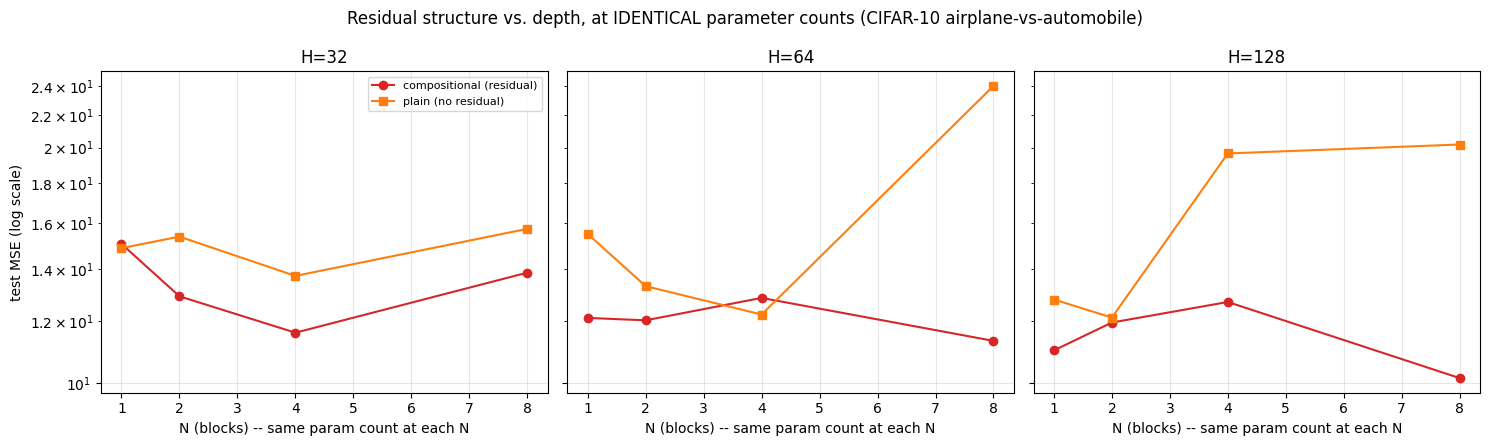

In [3]:
from collections import defaultdict

by_h = defaultdict(lambda: defaultdict(dict))
for r in results:
    if r["arch"] in ("compositional_relu", "deep_plain_mlp"):
        h = int(r["cfg_hidden"])
        n = int(r["cfg_n_blocks"]) if r["arch"] == "compositional_relu" else int(r["cfg_n_layers"]) // 3
        by_h[h][n][r["arch"]] = r["test_mse"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, h in zip(axes, sorted(by_h)):
    ns = sorted(by_h[h])
    comp = [by_h[h][n].get("compositional_relu") for n in ns]
    plain = [by_h[h][n].get("deep_plain_mlp") for n in ns]
    ax.plot(ns, comp, "o-", color=ARCH_STYLE["compositional_relu"]["color"], label="compositional (residual)")
    ax.plot(ns, plain, "s-", color=ARCH_STYLE["deep_plain_mlp"]["color"], label="plain (no residual)")
    ax.set_title(f"H={h}")
    ax.set_xlabel("N (blocks) -- same param count at each N")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("test MSE (log scale)")
axes[0].legend(fontsize=8)
fig.suptitle("Residual structure vs. depth, at IDENTICAL parameter counts (CIFAR-10 airplane-vs-automobile)")
fig.tight_layout()
plt.show()

## Worst-case disagreements: unprecedented in this series

For the first time across all four distillation experiments, **all 16 of
the top 16** worst disagreements are genuine classification flips -- and
many are images the teacher was highly confident and *correct* about that
the student confidently gets backwards. Not near-boundary ambiguity; a
real representational gap.

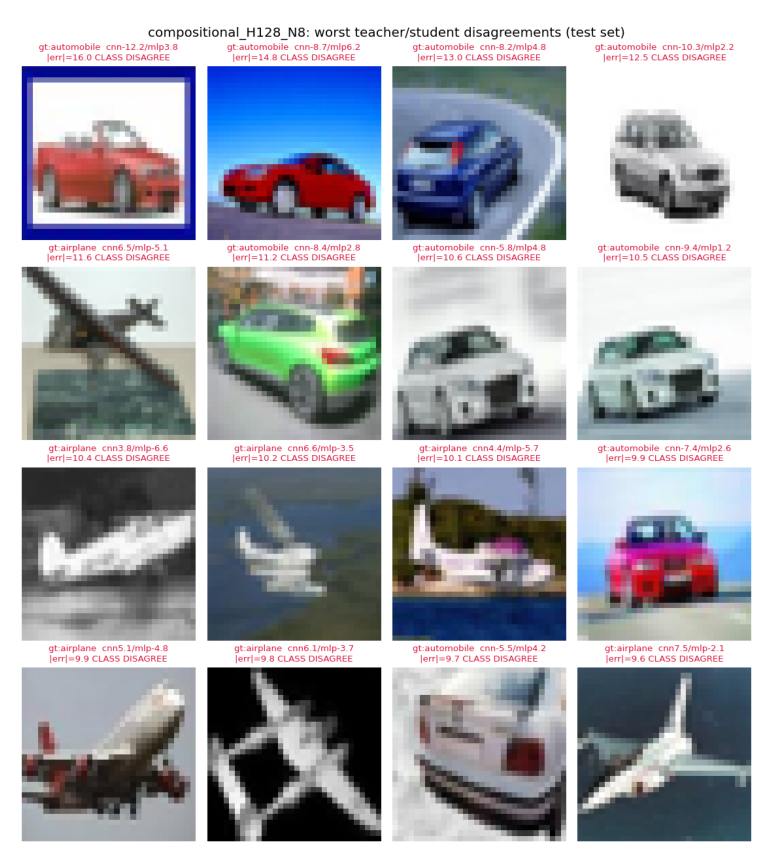

In [4]:
img = mpimg.imread(OUTPUTS / "worst_cases" / "compositional_H128_N8_worst_cases.png")
plt.figure(figsize=(11, 11))
plt.imshow(img)
plt.axis("off")
plt.show()

## Ground-truth task evaluation

In [5]:
for name in ["conventional_mlp_H32", "compositional_H128_N8"]:
    path = OUTPUTS / f"ground_truth_eval_{name}.csv"
    with open(path) as f:
        rows = list(csv.DictReader(f))
    test_row = next(r for r in rows if r["split"] == "test" and r["who"] == "student")
    teacher_row = next(r for r in rows if r["split"] == "test" and r["who"] == "teacher")
    print(f"{name}: student acc={float(test_row['accuracy']):.4f} recall={float(test_row['recall']):.4f}  "
          f"(teacher acc={float(teacher_row['accuracy']):.4f} recall={float(teacher_row['recall']):.4f})")

print("\nBoth students land 8-11 accuracy points below the teacher -- and more capacity")
print("(99k -> 790k params, 8x) only narrows that gap by ~3 points. Compare experiment 09,")
print("where the smallest MLP was already within 1.2 points of its teacher.")

conventional_mlp_H32: student acc=0.8415 recall=0.8070  (teacher acc=0.9525 recall=0.9420)
compositional_H128_N8: student acc=0.8705 recall=0.8560  (teacher acc=0.9525 recall=0.9420)

Both students land 8-11 accuracy points below the teacher -- and more capacity
(99k -> 790k params, 8x) only narrows that gap by ~3 points. Compare experiment 09,
where the smallest MLP was already within 1.2 points of its teacher.


## Takeaways

- **Balance does not generally make distillation easier.** Experiment 09
  (MNIST) said yes; this experiment (CIFAR-10) says no, decisively. The
  real driver is how visually/texturally close the two compared classes
  are, not whether the task is balanced.
- **Automobile is a "hard negative" for airplane** in a way that "9 mixed
  classes averaged together" isn't -- both are metal objects on clean
  backgrounds, forcing the teacher to learn a finer-grained, more
  nonlinear decision function than the broad, diverse one-vs-rest task
  needed. That finer function is much harder for a flat MLP to represent.
- **The plain-vs-residual gap is at its most dramatic here** -- outright
  training collapse at high depth, not gradual decline, the clearest
  demonstration in the series of why residual connections matter.
- **The Gaussian-noise exception is now 4-for-4** across every
  distillation experiment run -- the single most reliable finding in the
  whole series.
- **Why this experiment matters:** without it, experiment 09 alone would
  have supported a tidy but wrong generalization. Four experiments across
  two datasets and two axes of variation (task difficulty, task balance)
  tell a more honest, narrower story than any one of them could.

Full write-up:
`experiments/11_function_distillation_airplane_vs_automobile/README.md`.